# Dataset description
## Share of education attainment in people aged 25-64

Source: [OECD](https://data-explorer.oecd.org/vis?fs[0]=Topic,1%7CEducation%20and%20skills%23EDU%23%7CEducation%20attainment%23EDU_ATT%23&pg=0&fc=Topic&bp=true&snb=6&vw=tb&df[ds]=dsDisseminateFinalDMZ&df[id]=DSD_EAG_LSO_EA%40DF_LSO_NEAC_DISTR_EA&df[ag]=OECD.EDU.IMEP&df[vs]=1.0&dq=COL._T.Y25T64.ISCED11A_0T2%2BISCED11A_3_4%2BISCED11A_5T8..........OBS...A&pd=1997,2025&to[TIME_PERIOD]=true)

# Code
## Imports

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

## Load data

In [2]:
path = "./data/education_share.csv"

cols = [
    "Educational attainment level", "TIME_PERIOD", "OBS_VALUE"
]
df = pd.read_csv(path, encoding="utf-8", usecols=cols)

## Clean data

In [3]:
df_f = df.dropna()

attainment = []

for level in df_f["Educational attainment level"].unique():
    tmp = df_f[df_f["Educational attainment level"].eq(level)]
    attainment.append(tmp)

## Plot

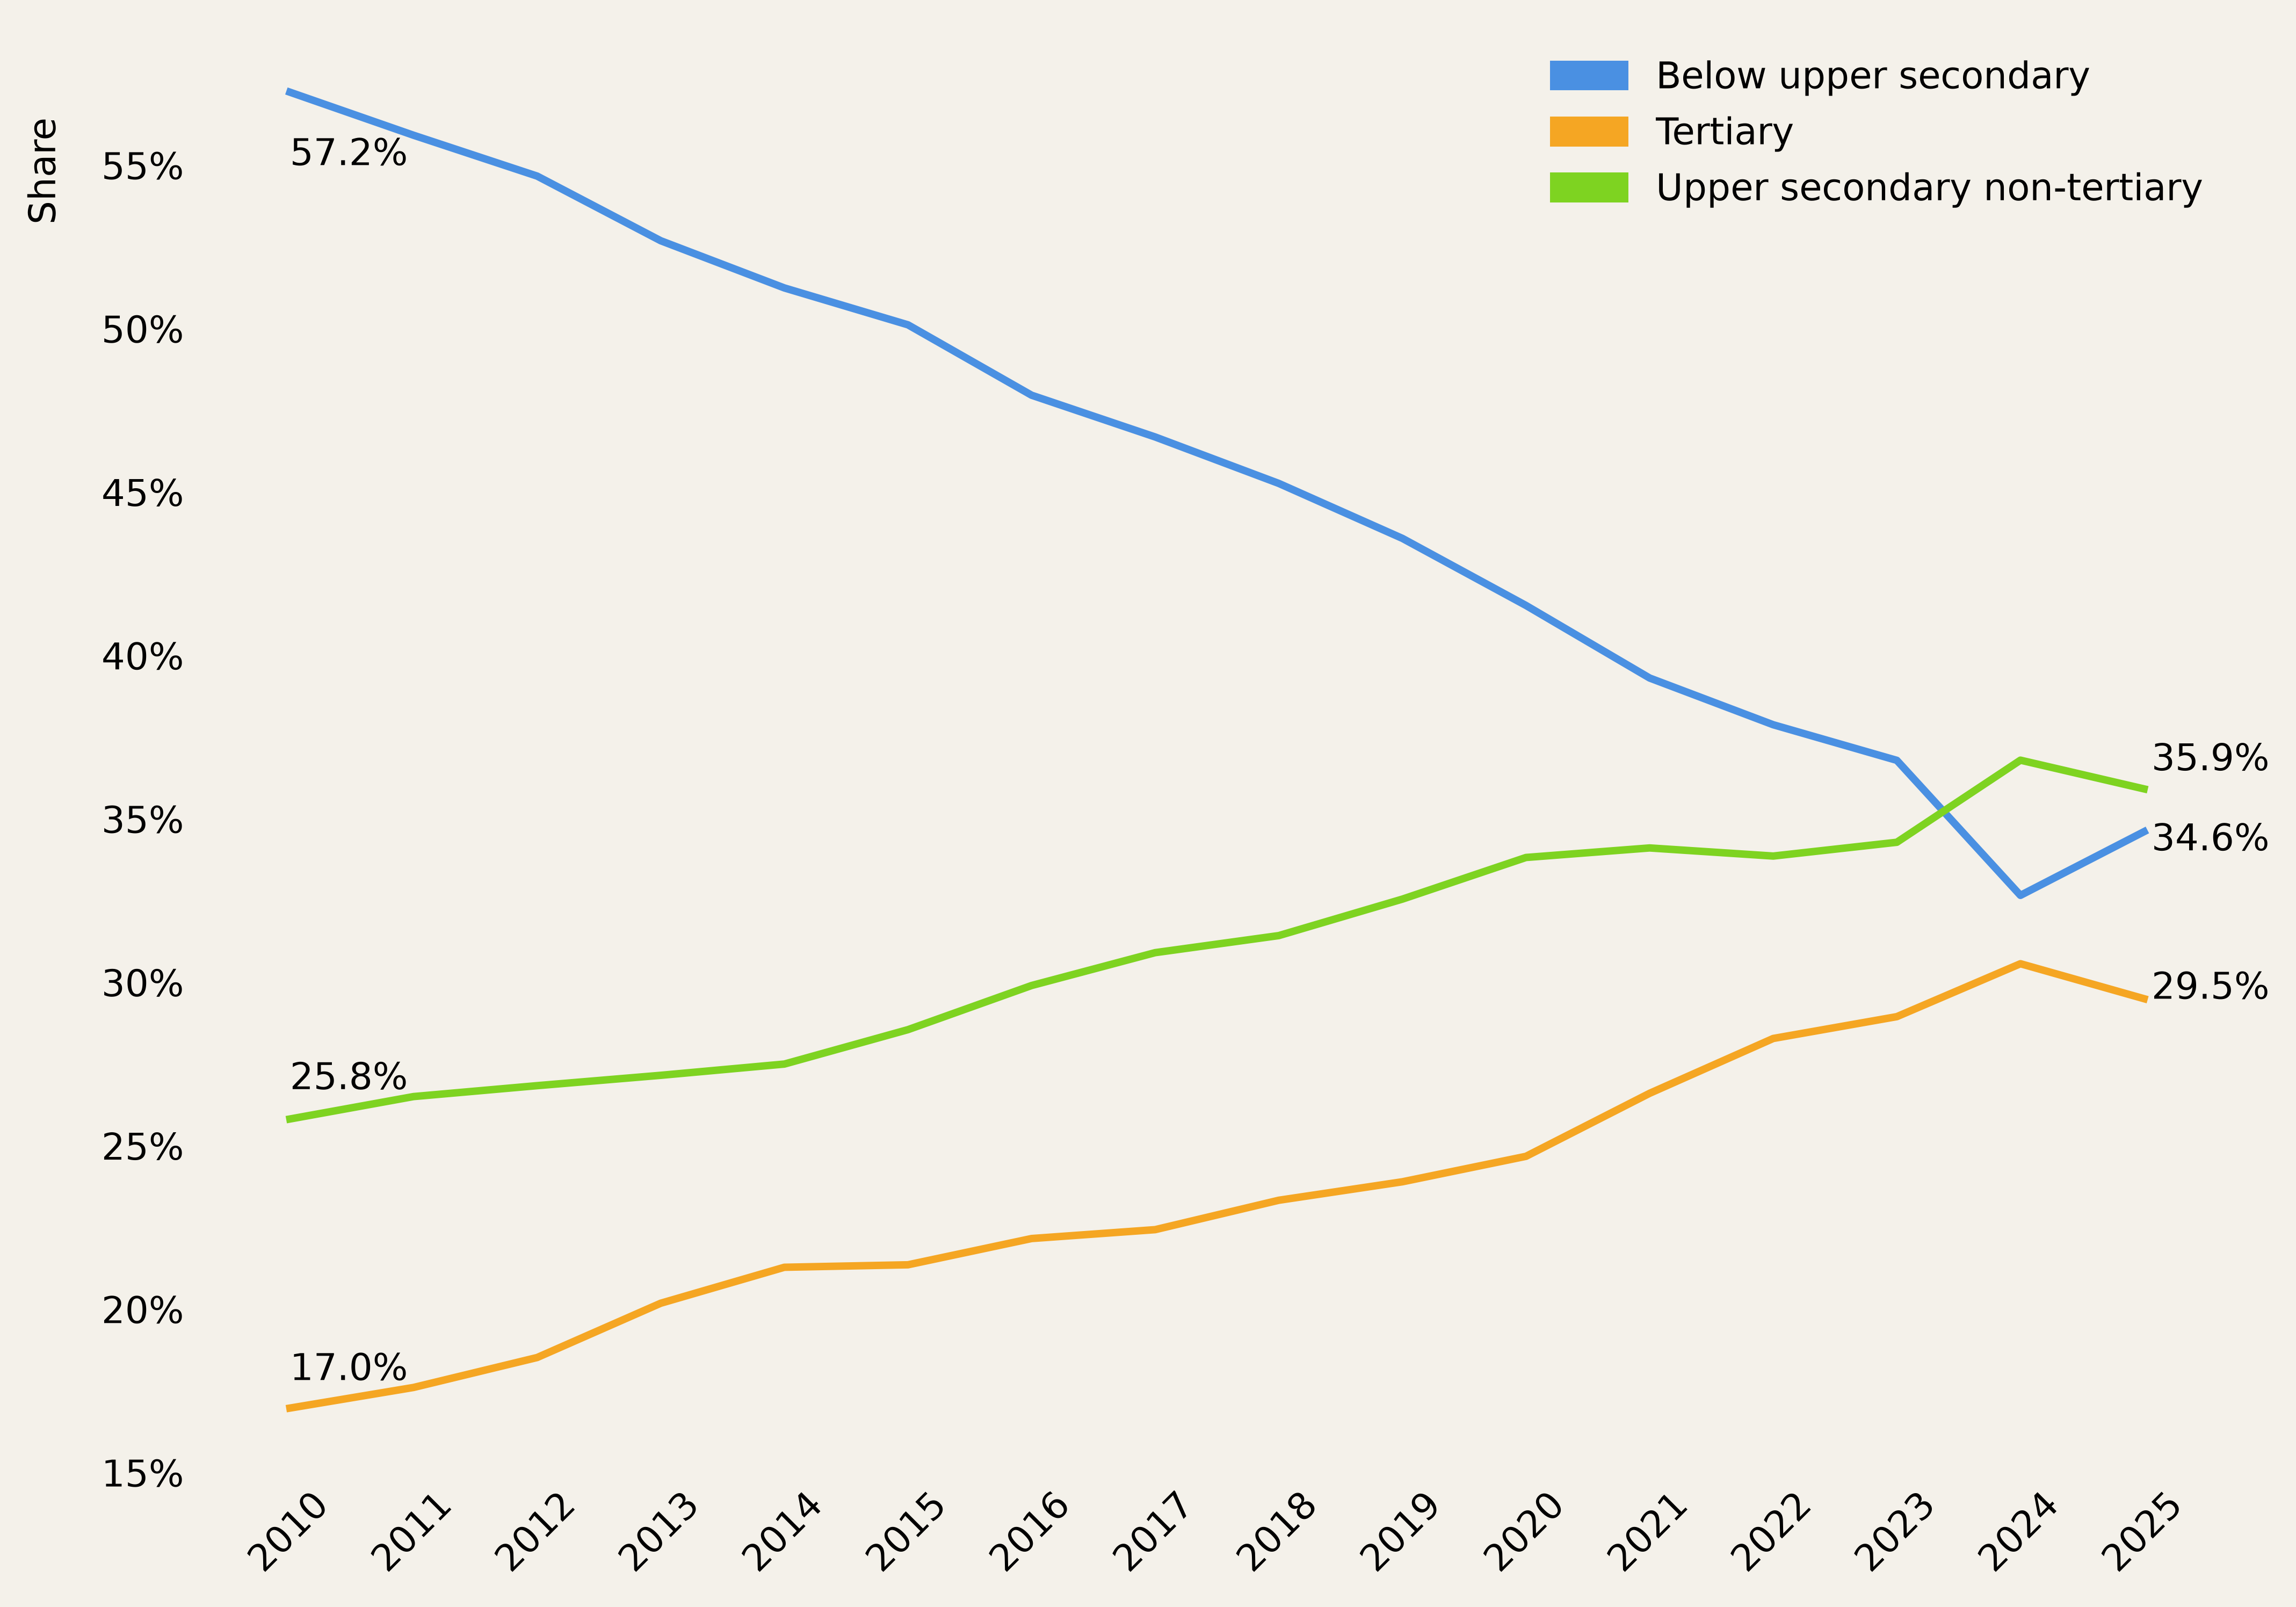

In [26]:
background = "#F4F1EA"
colors = ["#4A90E2", "#F5A623", "#7ED321"]
x_axis = df_f["TIME_PERIOD"].unique()
y_offset = [-5, 0, 5]
y_offset_2010 = [-8, 2, 2]

fig, ax = plt.subplots(figsize=(9.8, 7.0), dpi=500)
fig.patch.set_facecolor(background)
ax.patch.set_facecolor(background)

for i in range(len(df_f["Educational attainment level"].unique())):
    values = attainment[i]["OBS_VALUE"]

    plt.plot(
        x_axis, 
        values, 
        color=colors[i], 
        linewidth=2, 
    )

    plt.annotate(
        f"{values.iloc[-1]:.1f}%",
        xy = (x_axis[-1], values.iloc[-1]),
        xytext = (2, y_offset[i]),
        textcoords = "offset points"
    )

    plt.annotate(
        f"{values.iloc[0]:.1f}%",
        xy = (x_axis[0], values.iloc[1]),
        xytext = (0, y_offset_2010[i]),
        textcoords = "offset points"
    )

plt.xticks(x_axis, rotation=45)

for side in ["top", "bottom", "left", "right"]:
    plt.gca().spines[side].set_visible(False)

for axis in ["y", "x"]:
    plt.tick_params(axis=axis, length=0)

plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0f}%"))

plt.ylabel("Share", labelpad=10, fontsize=10, y=0.9)

handles = [
    Patch(color=colors[0], label="Below upper secondary"),
    Patch(color=colors[1], label="Tertiary"),
    Patch(color=colors[2], label="Upper secondary non-tertiary")
]

plt.legend(
    handles=handles,
    frameon=False

)

plt.show()